In [98]:
# %pip install yfinance pandas numpy matplotlib seaborn scipy statsmodels scikit-learn ipykernel requests beautifulsoup4 lxml python-dateutil

In [99]:

# Import libraries
import yfinance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, bds
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
import yfinance as yf  # my code uses the 'yf' alias
from sklearn.linear_model import RidgeCV, LassoCV, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error
from statsmodels.stats.outliers_influence import variance_inflation_factor
# NOTE: Should not download the getFamaFrench_factors.py file off the internet,
# Martin says that you should only use the file from the course.

In [100]:
TICKER = "MRK"
START = "2010-01-01"

In [101]:
# FamaFrench Factors must be manually loaded. getFamaFrench_factors.py must be uploaded everytime you start runtime.
import getFamaFrench_factors as gff

In [102]:
# MRK is the dicker for assigned company.
mrk = yfinance.Ticker('MRK')

In [103]:
# Specify the last 2 years.
ts_daily = mrk.history(period = '2y', interval = '1d')
ts_hourly = mrk.history(period = '2y', interval = '1h')

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpl

In [104]:
print("Daily observations:", len(ts_daily))
print("Hourly observations:", len(ts_hourly))

print("Daily data starts:", ts_daily.index.min())
print("Daily data ends:", ts_daily.index.max())

print("Hourly data starts:", ts_hourly.index.min())
print("Hourly data ends:", ts_hourly.index.max())

Daily observations: 501
Hourly observations: 3477
Daily data starts: 2024-10-31 00:00:00-04:00
Daily data ends: 2026-10-30 00:00:00-04:00
Hourly data starts: 2024-10-31 09:30:00-04:00
Hourly data ends: 2026-10-30 15:30:00-04:00


In [105]:
# Construct new dataframe for log return
# Must use 'Close' prices.
# Drop any NaN - includes 0s?
log_return_daily = np.log(ts_daily['Close'] / (ts_daily['Close'].shift(1))).dropna()
log_return_hourly = np.log(ts_hourly['Close'] / (ts_hourly['Close'].shift(1))).dropna()

# Question 2

Text(0, 0.5, 'Close (%)')

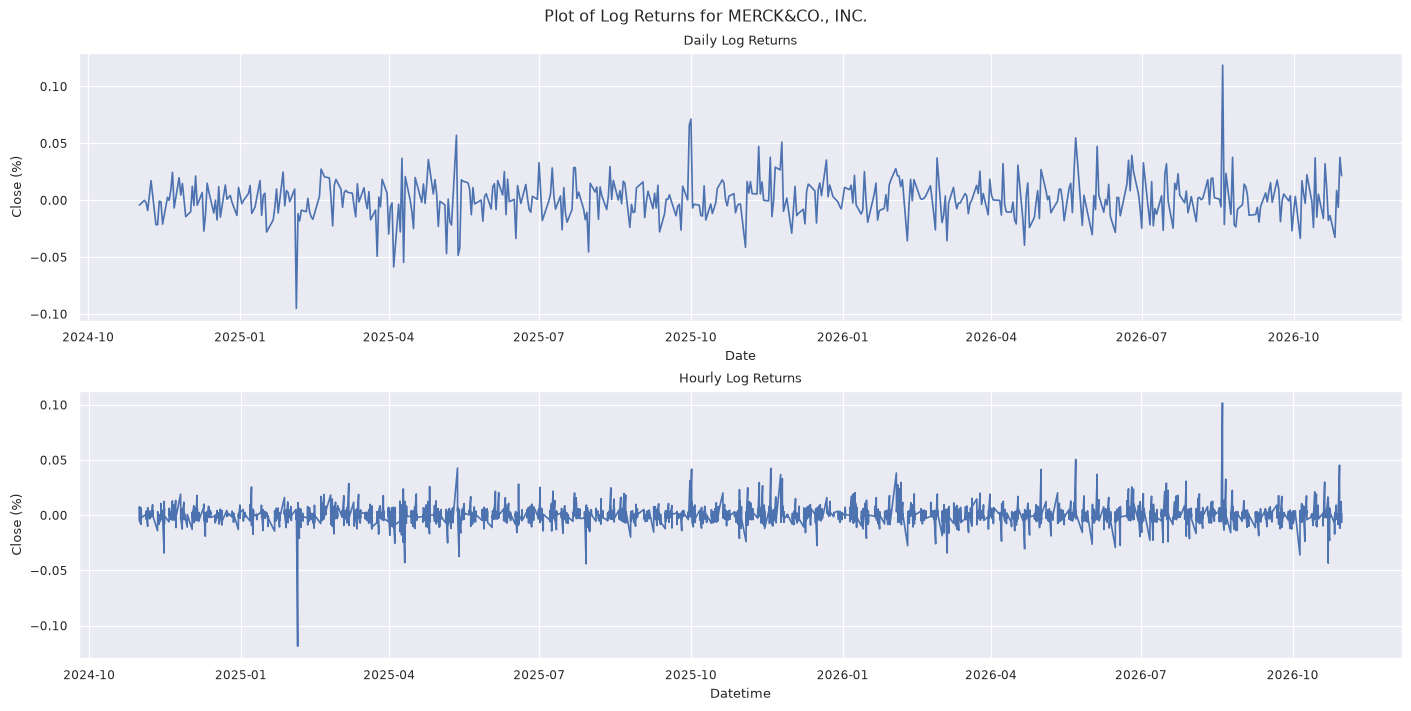

In [106]:
# Set theme & style(cosmetric)
sns.set_theme('paper')
sns.set_style('darkgrid')
# Plot log-returns over time.
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (14, 7), layout = 'constrained')

sns.lineplot(data = log_return_daily, ax = axes[0])
sns.lineplot(data = log_return_hourly, ax = axes[1])

fig.suptitle("Plot of Log Returns for MERCK&CO., INC.")
axes[0].set_title("Daily Log Returns")
axes[1].set_title("Hourly Log Returns")
axes[0].set_ylabel("Close (%)")
axes[1].set_ylabel("Close (%)")

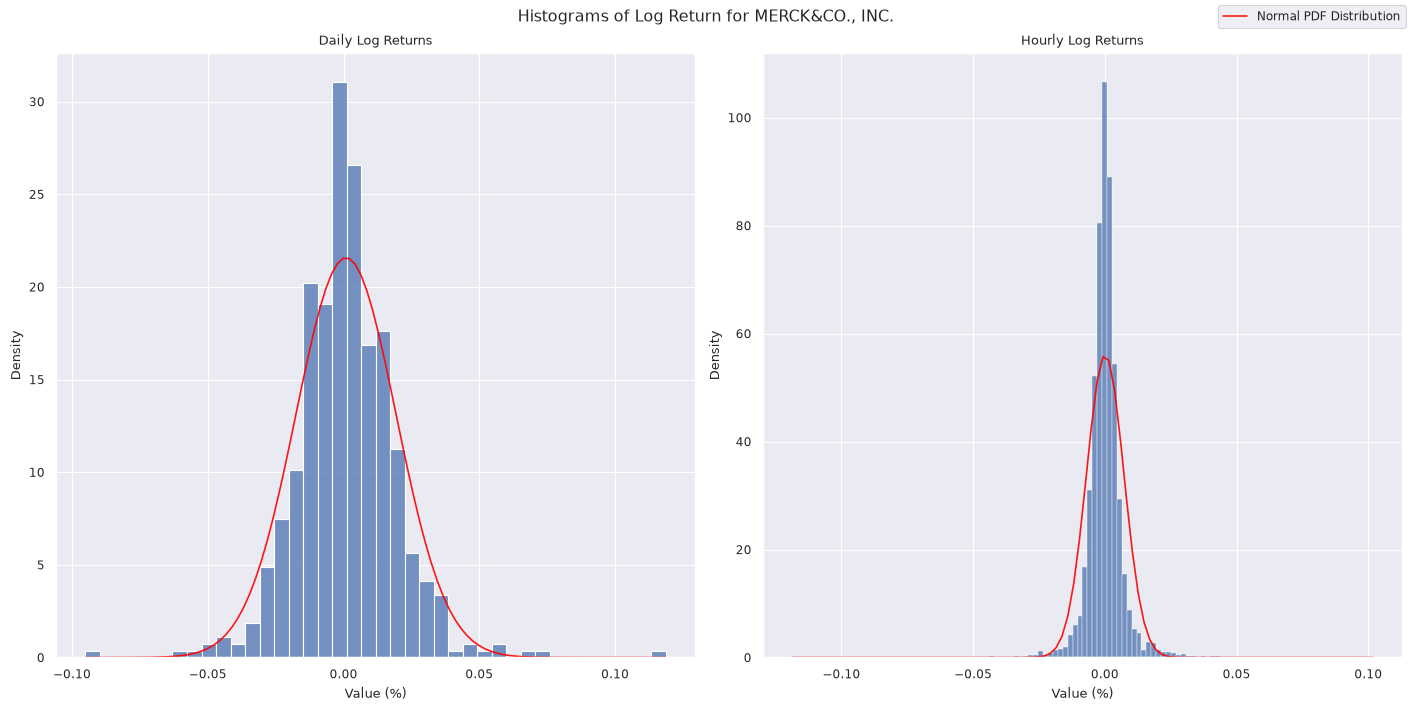

In [107]:
# Set theme & style(cosmetric)
sns.set_theme('paper')
sns.set_style('darkgrid')
# Plot log_return over normal distribution.
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14, 7), layout = 'constrained')

sns.histplot(x = log_return_daily, stat = 'density', ax = axes[0])
sns.histplot(x = log_return_hourly, stat = 'density', ax = axes[1])

# Fit log returns to normal distribution.
mu_daily, std_daily = stats.norm.fit(log_return_daily)
mu_hourly, std_hourly = stats.norm.fit(log_return_hourly)

# Generate x values over normal PDF.
x_daily = np.linspace(min(log_return_daily), max(log_return_daily), 100)
x_hourly = np.linspace(min(log_return_hourly), max(log_return_hourly), 100)

pdf_daily = stats.norm.pdf(x_daily, mu_daily, std_daily)
pdf_hourly = stats.norm.pdf(x_hourly, mu_hourly, std_hourly)

sns.lineplot(x = x_daily, y = pdf_daily, ax = axes[0], alpha = 0.9, color = 'red', label = 'Normal PDF Distribution', legend = False)
sns.lineplot(x = x_hourly, y = pdf_hourly, ax = axes[1], alpha = 0.9, color = 'red', legend = False)

handles, labels = axes[0].get_legend_handles_labels()

axes[0].set_title("Daily Log Returns")
axes[1].set_title("Hourly Log Returns")
axes[0].set_xlabel("Value (%)")
axes[1].set_xlabel("Value (%)")
fig.suptitle("Histograms of Log Return for MERCK&CO., INC.")
fig.legend(handles, labels, loc="upper right")

Text(0.5, 1.0, 'Plot of Hourly Log Returns')

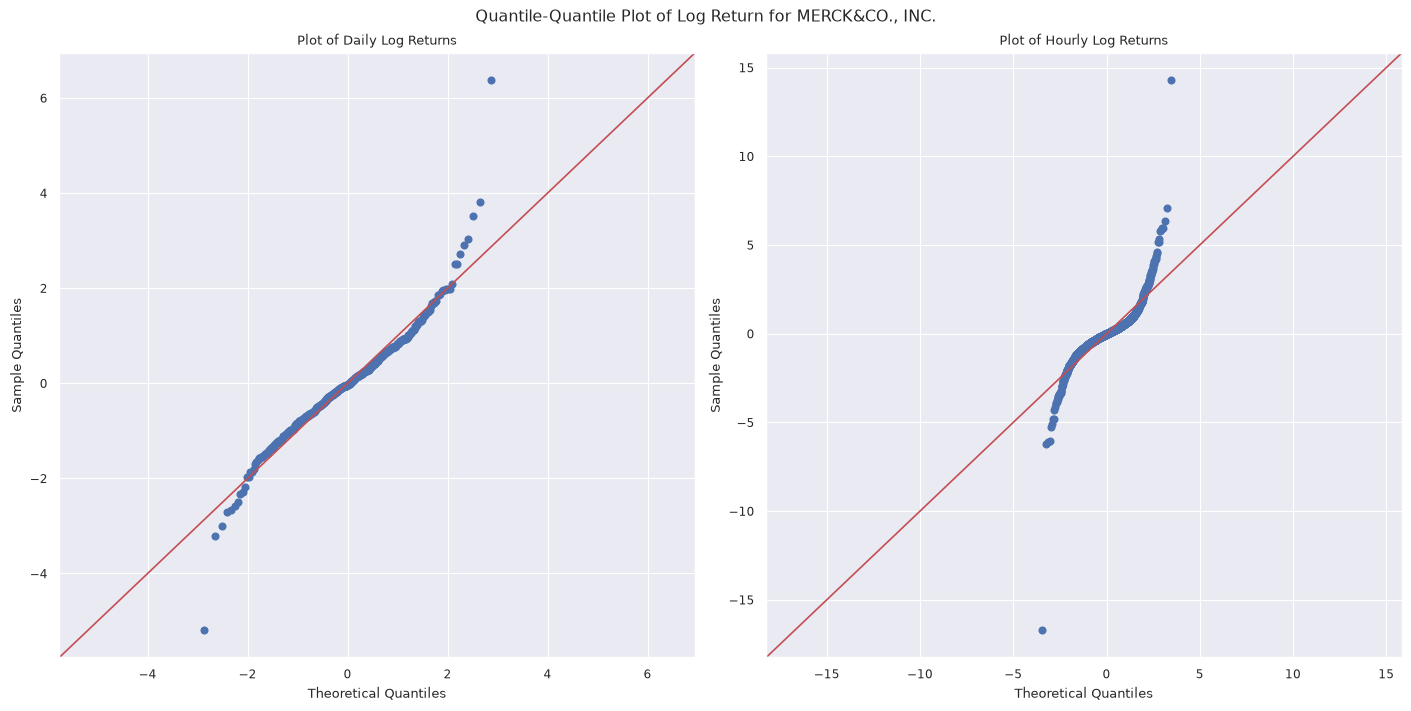

In [108]:
# Plot QQ
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize = (14, 7), layout = 'constrained')

# Set Seaborn Cosmetric
sns.set_theme('paper')
sns.set_style('darkgrid')

# Use statsmodel's QQPlot function
sm.qqplot(log_return_daily, dist = stats.norm, line = '45', fit = 'True', ax = axes[0])
sm.qqplot(log_return_hourly, dist = stats.norm, line = '45', fit = 'True', ax = axes[1])

fig.suptitle("Quantile-Quantile Plot of Log Return for MERCK&CO., INC.")
axes[0].set_title("Plot of Daily Log Returns")
axes[1].set_title("Plot of Hourly Log Returns")

In [109]:
# Display descriptive stats for daily and hourly series.
ts_daily['Close'].agg(['mean', 'std', 'skew', 'kurtosis'])

mean        101.687027
std          22.470604
skew          0.642863
kurtosis     -0.647296
Name: Close, dtype: float64

In [110]:
ts_hourly['Close'].agg(['mean', 'std', 'skew', 'kurtosis'])

mean        104.520673
std          21.379379
skew          0.594421
kurtosis     -0.638369
Name: Close, dtype: float64

In [111]:
# Descriptive statistics for hourly and daily log returns

ts_descriptive_stats = pd.concat(
    [log_return_hourly, log_return_daily],
    axis=1,
    keys=['Hourly Log Returns', 'Daily Log Returns']
)

ts_descriptive_stats.agg(
    ['mean', 'std', 'skew', 'kurtosis']
).T

/tmp/ipykernel_1450/1648866777.py:3: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  ts_descriptive_stats = pd.concat(


,mean,std,skew,kurtosis
Hourly Log Returns,0.000110,0.007113,-0.098455,40.700169
Daily Log Returns,0.000889,0.018512,0.371692,5.125844


# Question 3

## Part A

In [112]:
# Load max period for MRK
ts_daily_max = mrk.history(period = 'max', interval = '1d')

# Simple Returns, 'Close' is automatically adjusted in recent versions.
mrk_return_daily = ts_daily_max['Close'].pct_change().dropna()

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inpl

In [113]:
# S&P500 - ticker: ^GSPC
snp500 = yfinance.Ticker('^GSPC')
# T-Bill
t_bill = yfinance.Ticker('^IRX')

In [114]:
# 3 month / 13 week
# Specify max period to ensure that calculations are accurately.
snp500_daily = snp500.history(period = 'max', interval = '1d')
t_bill_rr = t_bill.history(period = 'max', interval = '1d')

# Strip timezone so it aligns with tz-naive.
snp500_daily.index = pd.to_datetime(snp500_daily.index).tz_localize(None).normalize()
t_bill_rr.index = pd.to_datetime(t_bill_rr.index).tz_localize(None).normalize()

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=

In [115]:
# pct_change calculates simple returns
snp500_daily_return = snp500_daily['Close'].pct_change().dropna()
t_bill_rr = t_bill_rr['Close']

In [116]:
# Load Fama-French Factors
# NOTE: You must upload getFamaFrench_factors everytime you start runtime (files get auto deleted everytime runtime is terminated).
ff3_data = gff.famaFrench3Factor(frequency = 'd')

In [117]:
# Set Index to Date
ff3_data.set_index('Date', inplace = True)

/tmp/ipykernel_1450/2730558795.py:2: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  ff3_data.set_index('Date', inplace = True)


In [118]:
ff3_data

,Mkt-RF,SMB,HML,RF
Date,,,,
1926-07-01,0.0009,-0.0023,-0.0028,0.0001
1926-07-02,0.0045,-0.0034,-0.0003,0.0001
1926-07-06,0.0017,0.0029,-0.0038,0.0001
1926-07-07,0.0009,-0.0062,0.0003,0.0001
1926-07-08,0.0022,-0.0038,0.0018,0.0001
...,...,...,...,...
2026-09-23,-0.0080,-0.0096,0.0030,0.0001
2026-09-24,-0.0004,-0.0019,0.0023,0.0001
2026-09-25,0.0043,-0.0038,0.0041,0.0001


In [119]:
# Check which has timezone signatures.
# This is tz-naive
ff3_data.index.tz
# This is tz-aware
snp500_daily_return.index.tz

In [120]:
# Merge S&P500 Simple Returns, T-Bill and FF3 data.
snp500_daily_return.name = 'SNP500_ret'
t_bill_rr.name = 'T-Bill_rr'

ff3_new = pd.concat([ff3_data, snp500_daily_return, t_bill_rr], axis = 1, join = 'inner')

In [121]:
ff3_new

,Mkt-RF,SMB,HML,RF,SNP500_ret,T-Bill_rr
Date,,,,,,
1960-01-04,-0.0003,0.0060,0.0067,0.0002,0.000334,4.520
1960-01-05,0.0078,-0.0038,0.0052,0.0002,0.008012,4.550
1960-01-06,-0.0047,0.0013,0.0036,0.0002,-0.004305,4.680
1960-01-07,-0.0065,0.0035,0.0011,0.0002,-0.007318,4.630
1960-01-08,-0.0033,0.0019,0.0007,0.0002,-0.003183,4.590
...,...,...,...,...,...,...
2026-09-23,-0.0080,-0.0096,0.0030,0.0001,-0.007548,4.028
2026-09-24,-0.0004,-0.0019,0.0023,0.0001,-0.000247,4.068
2026-09-25,0.0043,-0.0038,0.0041,0.0001,0.005099,4.070


In [122]:
# Calculate Excess Returns for snp500.
# Trading days depend on 250 - 253 trading days.
# PS Edmund - 'I will use 252 trading days.
SNP500_ret_ex = ff3_new['SNP500_ret'] - ff3_new['RF']

Text(0, 0.5, 'S&P 500 Excess Return (decimal)')

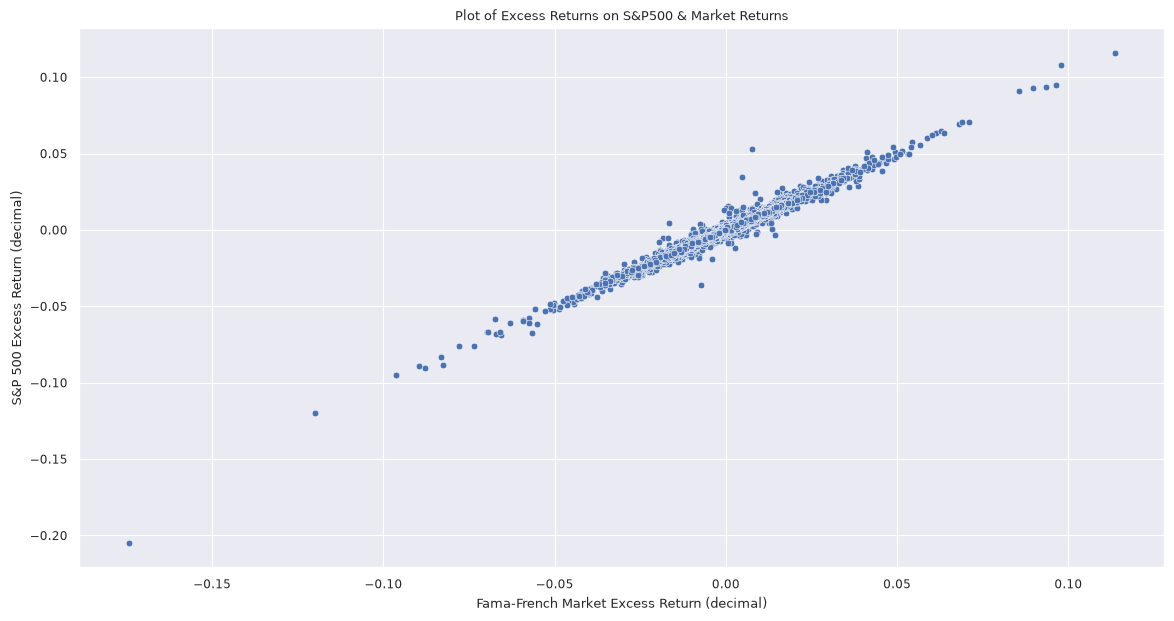

In [123]:
# Plot Excess Returns against
fig, ax = plt.subplots(figsize = (14, 7))

sns.scatterplot(y = SNP500_ret_ex, x = ff3_new['Mkt-RF'], ax = ax)
ax.set_title("Plot of Excess Returns on S&P500 & Market Returns")
ax.set_xlabel("Fama-French Market Excess Return (decimal)")
ax.set_ylabel("S&P 500 Excess Return (decimal)")

## Part B


In [124]:
# Convert annual T-bill yield to a daily rate using compounding
annual_rate = ff3_new['T-Bill_rr'] / 100

# Use 252 trading days
ff3_new['T-Bill_rr'] = (1 + annual_rate) ** (1 / 252) - 1

# Compare daily T-bill rate with Fama-French RF
ff3_new[['T-Bill_rr', 'RF']].head()

,T-Bill_rr,RF
Date,,
1960-01-04,0.000175,0.0002
1960-01-05,0.000177,0.0002
1960-01-06,0.000182,0.0002
1960-01-07,0.000180,0.0002
1960-01-08,0.000178,0.0002


Text(0, 0.5, 'Risk-Free Rate')

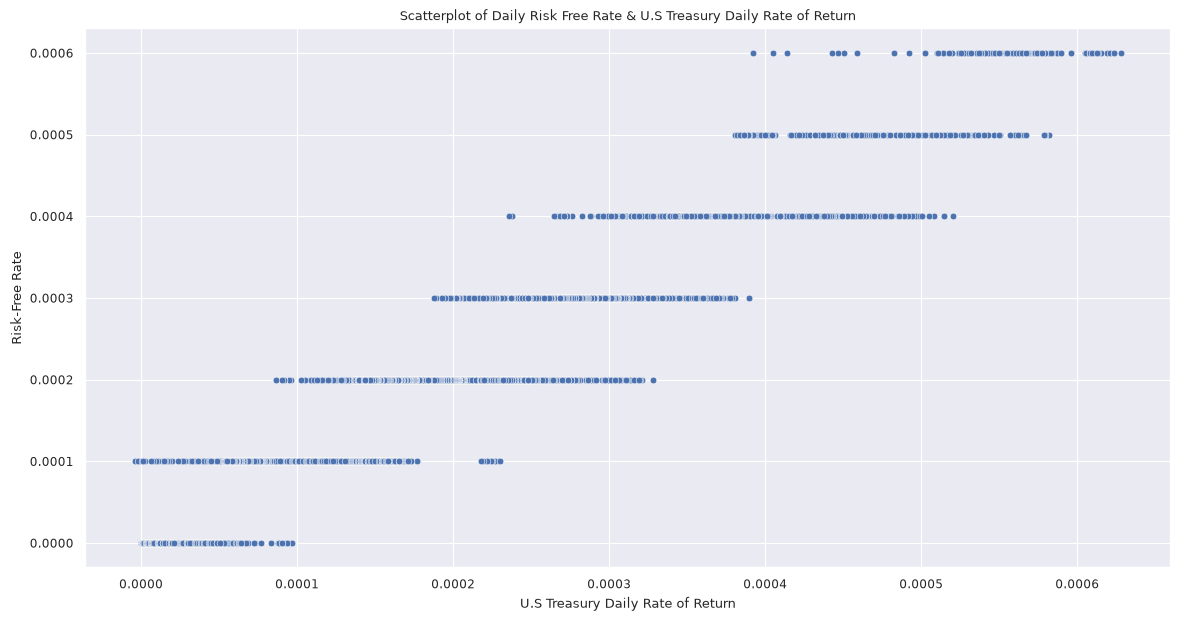

In [125]:
# Plot Scatterplot
fig, ax = plt.subplots(figsize = (14, 7))

sns.scatterplot(data = ff3_new, x = 'T-Bill_rr', y = 'RF', ax = ax)

ax.set_title("Scatterplot of Daily Risk Free Rate & U.S Treasury Daily Rate of Return")
ax.set_xlabel("U.S Treasury Daily Rate of Return")
ax.set_ylabel("Risk-Free Rate")

# Question 4 - CAPM

## Part A

Use HAC var-covar estimate.

In [126]:
# Fetch existing ff3 data.
ff3_mrk = ff3_new.copy()
# Strip tz timzone signatures to align with tz naive.
mrk_return_daily.name = 'MRK_rr'
mrk_return_daily.index = pd.to_datetime(mrk_return_daily.index).tz_localize(None).normalize()
# MRK simple returns daily for max period.
# Match MRK with FamaFrench 3 Data.
ff3_mrk = ff3_mrk.merge(mrk_return_daily, on = 'Date')

In [127]:
ff3_mrk

,Mkt-RF,SMB,HML,RF,SNP500_ret,T-Bill_rr,MRK_rr
Date,,,,,,,
1962-01-03,0.0024,0.0022,0.0096,0.0001,0.002396,0.000107,-0.041900
1962-01-04,-0.0084,0.0001,0.0066,0.0001,-0.006889,0.000107,-0.010203
1962-01-05,-0.0134,0.0007,0.0032,0.0001,-0.013873,0.000107,-0.033874
1962-01-08,-0.0075,0.0022,0.0032,0.0001,-0.007752,0.000109,0.003048
1962-01-09,0.0002,-0.0012,0.0034,0.0001,0.000434,0.000109,0.004560
...,...,...,...,...,...,...,...
2026-09-23,-0.0080,-0.0096,0.0030,0.0001,-0.007548,0.000157,-0.018753
2026-09-24,-0.0004,-0.0019,0.0023,0.0001,-0.000247,0.000158,-0.000675
2026-09-25,0.0043,-0.0038,0.0041,0.0001,0.005099,0.000158,0.005406


OLS Regression,  $${E[R_{it}] - R_{ft} = \alpha_{i} + \beta_{i}(E[R_{mt}] - R_{ft}) + \epsilon_{it}}$$ $${y = \alpha_{i} + \beta_{i}{X_1} + \epsilon_i}$$

In [128]:
# Compute Excess
y = ff3_mrk['MRK_rr'] - ff3_mrk['RF']
# Market Returns
X1 = ff3_mrk['Mkt-RF']

# Add Col to Intercept.
X1 = sm.add_constant(X1)

# Fit CAPM model.
capm_model = sm.OLS(y, X1).fit(cov_type = 'HAC', cov_kwds = {"maxlags": 5})

# Print Summary Results
print(capm_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.244
Model:                            OLS   Adj. R-squared:                  0.244
Method:                 Least Squares   F-statistic:                     1997.
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:23:27   Log-Likelihood:                 46485.
No. Observations:               16172   AIC:                        -9.297e+04
Df Residuals:                   16170   BIC:                        -9.295e+04
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0002      0.000      1.897      0.0

## Part B

In [129]:
# Extract alpha, beta values from part (a)
alpha_male, beta = capm_model.params['const'], capm_model.params['Mkt-RF']

This is expressed as $${E[R_A] = \beta_{A}E[R_m] + (1-\beta_{A})E[R_f]}$$

In [130]:
replic_ret = beta * ff3_mrk['SNP500_ret'] + (1 - beta) * ff3_mrk['T-Bill_rr']

In [131]:
replic_ret

Date
1962-01-03    0.001851
1962-01-04   -0.005224
1962-01-05   -0.010546
1962-01-08   -0.005881
1962-01-09    0.000357
                ...   
2026-09-23   -0.005715
2026-09-24   -0.000150
2026-09-25    0.003923
2026-09-28   -0.005839
2026-09-29   -0.001237
Length: 16172, dtype: float64

## Part C

Recall CAPM model: 
$${E[R_{it}] - R_{ft} = \alpha_{i} + \beta_{i}(E[R_{mt}] - R_{ft}) + \epsilon_{it}}$$
Rearrange, 
$${E[R_{it}] = \alpha_{i} + \beta_{i}(E[R_{mt}] - R_{ft}) + R_{ft} + \epsilon_{it}}$$

In [132]:
# Compute Expected Return & Varience for Merck & Co, Inc.
mrk_expected_ret = ff3_mrk['MRK_rr'].mean()
mrk_var = ff3_mrk['MRK_rr'].var()

# Compute Expected Return and Varience for Replicted Portfolio
replic_port_expected_ret = replic_ret.mean()
replic_port_var = replic_ret.var()

In [133]:
print(f"Expected Return - MRK: {mrk_expected_ret * 100}%")
print(f"Expected Return - Replicated Portfolio: {replic_port_expected_ret * 100}%")
print("")
print(f"Varience - MRK: {mrk_expected_ret}")
print(f"Varience - Replication Portfolio: {replic_port_var}")

Expected Return - MRK: 0.05759654242404908%
Expected Return - Replicated Portfolio: 0.02849038982495713%

Varience - MRK: 0.0005759654242404908
Varience - Replication Portfolio: 6.235410107143247e-05


In [134]:
# Define Sharpe Ratio
def compute_sharpe_ratio(returns, risk_free):
    excess = returns - risk_free
    result = excess.mean() / excess.std()
    return result

In [135]:
mrk_sr = compute_sharpe_ratio(ff3_mrk['MRK_rr'], ff3_mrk['T-Bill_rr'])
replic_sr = compute_sharpe_ratio(replic_ret, ff3_mrk['T-Bill_rr'])
snp500_sr = compute_sharpe_ratio(ff3_mrk['SNP500_ret'], ff3_mrk['T-Bill_rr'])

# Print Sharpe Ratios
print(f"The Sharpe Ratio of Merck & Co. Inc is {mrk_sr}")
print(f"The Sharpe Ratio of Replication Portfolio is {replic_sr}")
print(f"The Sharpe Ratio of S&P500 is {snp500_sr}")

The Sharpe Ratio of Merck & Co. Inc is 0.025890640942989186
The Sharpe Ratio of Replication Portfolio is 0.014655366435068498
The Sharpe Ratio of S&P500 is 0.0146553664350685


# Question 5

## Part A/B

In [136]:
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson
# Load famaFrench 5 factors.
ff5_data = gff.famaFrench5Factor(frequency = 'd')
ff5_data.set_index('Date')
ff5_data = ff5_data.merge(mrk_return_daily, on = 'Date')

ff5_factors = ["Mkt-RF", "SMB", "HML", "RMW", "CMA"]
# Dependent variable = MRK EXCESS return (MRK_rr - RF), same as the CAPM in Q4,
# because the factor model is written for excess returns.
y_full = ff5_data["MRK_rr"] - ff5_data["RF"]
X5 = sm.add_constant(ff5_data[ff5_factors])

# Classical OLS (used for AIC/BIC and diagnostics) and HAC version (used for inference)
ff5_ols = sm.OLS(y_full, X5).fit()
ff5_hac = sm.OLS(y_full, X5).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(ff5_hac.summary())

# Joint F-test: are all five factor loadings zero? (HAC-robust)
R = np.hstack([np.zeros((5, 1)), np.eye(5)])
print("\nJoint test that all factor loadings = 0:")
print(ff5_hac.f_test(R))

# Test of alpha (returns are decimals, so x100 gives % per day)
alpha_pct = ff5_hac.params['const'] * 100
print(f"\nAlpha = {alpha_pct:.4f}% per day (about {alpha_pct * 252:.1f}% per year), "
      f"t = {ff5_hac.tvalues['const']:.2f}, p = {ff5_hac.pvalues['const']:.4f}")

# Residual diagnostics
bp_stat, bp_p, _, _ = het_breuschpagan(ff5_ols.resid, X5)
print(f"\nDurbin-Watson: {durbin_watson(ff5_ols.resid):.3f}")
print(f"Breusch-Pagan p-value (heteroskedasticity): {bp_p:.4f}")
print(f"Jarque-Bera p-value (normality): {stats.jarque_bera(ff5_ols.resid)[1]:.4f}")

# CAPM vs FF5 on the SAME sample (the Q4 CAPM used 1962 onwards, FF5 data starts 1963)
capm_same = sm.OLS(y_full, sm.add_constant(ff5_data[["Mkt-RF"]])).fit()
f_capm, p_capm, _ = ff5_ols.compare_f_test(capm_same)
print(f"\nCAPM (same sample) R2 = {capm_same.rsquared:.4f}  vs  FF5 R2 = {ff5_ols.rsquared:.4f}")
print(f"Nested F-test (CAPM vs FF5): F = {f_capm:.2f}, p = {p_capm:.4g}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.292
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     564.0
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:23:29   Log-Likelihood:                 46251.
No. Observations:               15917   AIC:                        -9.249e+04
Df Residuals:                   15911   BIC:                        -9.244e+04
Df Model:                           5                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0001      0.000      1.131      0.2

## Part C


In [137]:
# Load famaFrench 5 factors.
ff5_data = gff.famaFrench5Factor(frequency = 'd')
ff5_data.set_index('Date')
ff5_data = ff5_data.merge(mrk_return_daily, on = 'Date')
# Load Momentum Factors.
mom_data = gff.momentumFactor(frequency = 'd')
mom_data = mom_data.set_index('Date')
ff6_data = ff5_data.merge(mom_data, on = 'Date')

ff6_factors = ff5_factors + ["MOM"]
X6 = sm.add_constant(ff6_data[ff6_factors])

ff6_ols = sm.OLS(y_full, X6).fit()
ff6_hac = sm.OLS(y_full, X6).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(ff6_hac.summary())

print(f"\nMomentum loading = {ff6_hac.params['MOM']:.4f}, "
      f"t = {ff6_hac.tvalues['MOM']:.2f}, p = {ff6_hac.pvalues['MOM']:.4f}")

# Side-by-side comparison of FF5 vs FF5 + Momentum
comparison = pd.DataFrame({
    "R2": [ff5_ols.rsquared, ff6_ols.rsquared],
    "Adj R2": [ff5_ols.rsquared_adj, ff6_ols.rsquared_adj],
    "AIC": [ff5_ols.aic, ff6_ols.aic],
    "BIC": [ff5_ols.bic, ff6_ols.bic],
}, index=["FF5", "FF5 + Momentum"])
print("\n", comparison.round(4))

# Nested F-test: does adding Mom significantly improve the fit?
f_stat, f_p, df_diff = ff6_ols.compare_f_test(ff5_ols)
print(f"\nNested F-test (FF5 vs FF5 + Mom): F = {f_stat:.3f}, p = {f_p:.4f}")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.293
Model:                            OLS   Adj. R-squared:                  0.292
Method:                 Least Squares   F-statistic:                     475.2
Date:                Sun, 01 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:23:31   Log-Likelihood:                 46252.
No. Observations:               15917   AIC:                        -9.249e+04
Df Residuals:                   15910   BIC:                        -9.244e+04
Df Model:                           6                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0001      0.000      1.203      0.2

## Part D

In [138]:
# Uses ONLY the course file (gff) for the Fama-French data (no downloading from the internet),
# plus Yahoo Finance for the oil factor (WTI crude futures, CL=F).
# Everything below is in PERCENT (decimal returns x 100), as the penalty grids assume.

# 1) FF5 + Momentum, already merged with MRK in 5 C
ff6 = ff6_data.copy()
if "Date" in ff6.columns:
    ff6 = ff6.set_index("Date")
ff6.index = pd.to_datetime(ff6.index).tz_localize(None).normalize()

# 2) Oil factor: daily % change in WTI front-month futures
oil_px = yf.download("CL=F", start=START, auto_adjust=True, progress=False)["Close"].squeeze()
oil_px.index = pd.to_datetime(oil_px.index).tz_localize(None).normalize()
oil_ret = oil_px / oil_px.shift(1) - 1
# 20 Apr 2020: WTI settled NEGATIVE (-$37), so returns involving that price are meaningless. Drop them.
oil_ret[(oil_px <= 0) | (oil_px.shift(1) <= 0)] = np.nan
oil_ret.name = "Oil"

# 3) Merge and scale to percent
cols = ["MRK_rr", "RF"] + ff6_factors
df = ff6.loc[ff6.index >= START, cols].join(oil_ret, how="inner").dropna() * 100
df["ExcessRet"] = df["MRK_rr"] - df["RF"]

factors = ff6_factors + ["Oil"]        # ["Mkt-RF","SMB","HML","RMW","CMA","MOM","Oil"]
y = df["ExcessRet"]
X = df[factors]

print("merged sample:", df.shape, df.index.min().date(), "->", df.index.max().date())
print(df[["ExcessRet"] + factors].describe().round(3))
print("\nCorrelation matrix of factors (multicollinearity check):")
print(X.corr().round(2))

merged sample: (4205, 10) 2010-01-05 -> 2026-09-29
       ExcessRet    Mkt-RF       SMB       HML       RMW       CMA       MOM  \
count   4205.000  4205.000  4205.000  4205.000  4205.000  4205.000  4205.000   
mean       0.053     0.054    -0.005    -0.003     0.006     0.001     0.017   
std        1.377     1.110     0.635     0.775     0.506     0.434     0.992   
min       -9.863   -12.010    -4.580    -5.030    -2.230    -2.910   -14.390   
25%       -0.648    -0.400    -0.380    -0.390    -0.270    -0.220    -0.430   
50%        0.028     0.070    -0.010    -0.030     0.000    -0.010     0.070   
75%        0.762     0.600     0.350     0.370     0.270     0.210     0.540   
max       12.589     9.650     5.710     6.730     4.250     2.470     5.980   

            Oil  
count  4205.000  
mean      0.051  
std       2.634  
min     -24.588  
25%      -1.181  
50%       0.096  
75%       1.261  
max      37.662  

Correlation matrix of factors (multicollinearity check):
        

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns=

In [139]:
# 5 D: does oil add information beyond the Fama-French factors?
# For each base model, compare it with the same model plus Oil (same rows, 2010 onwards; df, y come from the data cell above).
def add_oil_test(base_cols):
    X0 = sm.add_constant(df[base_cols])
    X1 = sm.add_constant(df[base_cols + ["Oil"]])
    m0 = sm.OLS(y, X0).fit()                                              # without oil
    m1 = sm.OLS(y, X1).fit()                                              # with oil: AIC/BIC and nested F-test
    m1_hac = sm.OLS(y, X1).fit(cov_type="HAC", cov_kwds={"maxlags": 5})   # with oil: HAC inference on the loading
    f_stat, f_p, _ = m1.compare_f_test(m0)                                # does adding Oil improve the fit?
    return {
        "Oil loading": m1_hac.params["Oil"],
        "HAC t": m1_hac.tvalues["Oil"],
        "HAC p": m1_hac.pvalues["Oil"],
        "Nested F p": f_p,
        "Adj R2 without": m0.rsquared_adj,
        "Adj R2 with": m1.rsquared_adj,
        "BIC without": m0.bic,
        "BIC with": m1.bic,
    }

oil_results = pd.DataFrame({
    "FF5":             add_oil_test(ff5_factors),
    "FF5 + MOM":       add_oil_test(ff6_factors),
    "Mkt + SMB + CMA": add_oil_test(["Mkt-RF", "SMB", "CMA"]),
}).T
print(oil_results.round(4))

# Full regression with oil (FF5 + MOM + Oil), HAC standard errors
oil_model = sm.OLS(y, sm.add_constant(df[factors])).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(oil_model.summary())

                 Oil loading   HAC t   HAC p  Nested F p  Adj R2 without  \
FF5                  -0.0238 -2.9193  0.0035      0.0013          0.2387   
FF5 + MOM            -0.0246 -2.9870  0.0028      0.0009          0.2391   
Mkt + SMB + CMA      -0.0251 -3.1262  0.0018      0.0006          0.2383   

                 Adj R2 with  BIC without    BIC with  
FF5                   0.2404   13522.1089  13520.1420  
FF5 + MOM             0.2409   13527.3515  13524.6554  
Mkt + SMB + CMA       0.2403   13509.5817  13506.1737  
                            OLS Regression Results                            
Dep. Variable:              ExcessRet   R-squared:                       0.242
Model:                            OLS   Adj. R-squared:                  0.241
Method:                 Least Squares   F-statistic:                     119.6
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          1.07e-160
Time:                        05:23:32   Log-Likelihood:                -6729

## Part E

### Split the dataset into a Train and Test Set

In [140]:
split = int(len(df) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

# Standardise using TRAIN statistics only (penalised models need comparable scales)
scaler = StandardScaler().fit(X_train)
Xs_train = scaler.transform(X_train)
Xs_test = scaler.transform(X_test)

## OLS (baseline, with Newey-West HAC standard errors)

In [141]:
X_train_c = sm.add_constant(X_train)
ols = sm.OLS(y_train, X_train_c).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
print(ols.summary())

ols_pred = ols.predict(sm.add_constant(X_test, has_constant="add"))

# VIFs for multicollinearity
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series(
    [variance_inflation_factor(X_train_c.values, i + 1) for i in range(len(factors))],
    index=factors, name="VIF")
print("\nVariance inflation factors:\n", vif.round(2))

                            OLS Regression Results                            
Dep. Variable:              ExcessRet   R-squared:                       0.327
Model:                            OLS   Adj. R-squared:                  0.326
Method:                 Least Squares   F-statistic:                     139.6
Date:                Sun, 01 Nov 2026   Prob (F-statistic):          4.74e-181
Time:                        05:23:32   Log-Likelihood:                -5016.0
No. Observations:                3364   AIC:                         1.005e+04
Df Residuals:                    3356   BIC:                         1.010e+04
Df Model:                           7                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0157      0.019      0.848      0.3

##  Ridge Regression with L2 Penalty

In [142]:
tscv = TimeSeriesSplit(n_splits=5)

alphas_ridge = np.logspace(-3, 4, 100)
ridge = RidgeCV(alphas=alphas_ridge, cv=tscv).fit(Xs_train, y_train)
ridge_pred = ridge.predict(Xs_test)
print(f"Ridge best alpha: {ridge.alpha_:.4f}")

Ridge best alpha: 104.7616


## Lasso Regression with L1 penalty

In [143]:
# scikit-learn >= 1.7 replaced n_alphas with alphas=<int>; support both
try:
    lasso = LassoCV(alphas=100, cv=tscv, max_iter=50000, random_state=0).fit(Xs_train, y_train)
except (TypeError, ValueError):
    lasso = LassoCV(n_alphas=100, cv=tscv, max_iter=50000, random_state=0).fit(Xs_train, y_train)
lasso_pred = lasso.predict(Xs_test)
print(f"Lasso best alpha: {lasso.alpha_:.6f}")


Lasso best alpha: 0.015916


## Comparing Coefficients

        OLS (standardised)   Ridge   Lasso
Mkt-RF              0.8175  0.7811  0.7793
SMB                -0.1843 -0.1732 -0.1684
HML                -0.0421 -0.0279 -0.0004
RMW                -0.0049 -0.0068 -0.0000
CMA                 0.2556  0.2310  0.2022
MOM                 0.0413  0.0458  0.0440
Oil                -0.0543 -0.0440 -0.0320

Factors dropped by Lasso: ['RMW']


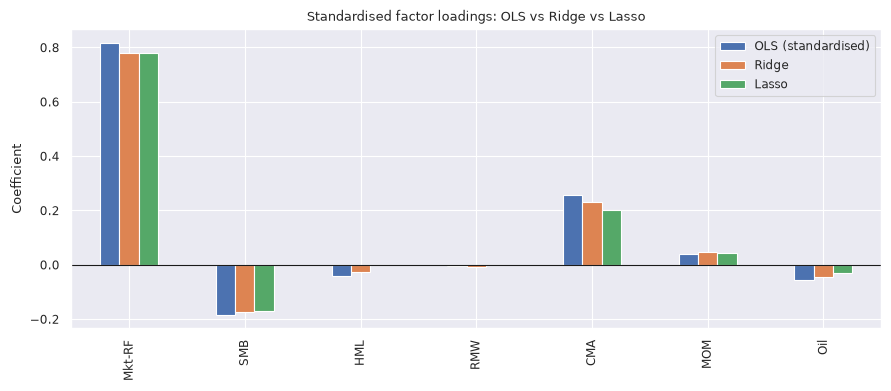

In [144]:
ols_std = sm.OLS(y_train, sm.add_constant(pd.DataFrame(Xs_train, columns=factors, index=X_train.index))).fit()

coef_table = pd.DataFrame({
    "OLS (standardised)": ols_std.params.drop("const"),
    "Ridge": pd.Series(ridge.coef_, index=factors),
    "Lasso": pd.Series(lasso.coef_, index=factors),
})
print(coef_table.round(4))
print("\nFactors dropped by Lasso:", [f for f, c in zip(factors, lasso.coef_) if c == 0] or "none")

coef_table.plot(kind="bar", figsize=(9, 4))
plt.title("Standardised factor loadings: OLS vs Ridge vs Lasso")
plt.axhline(0, color="k", lw=0.8)
plt.ylabel("Coefficient")
plt.tight_layout()
plt.show()

##  Regularisation Paths and how the coeficcients shrink as the penalty grows

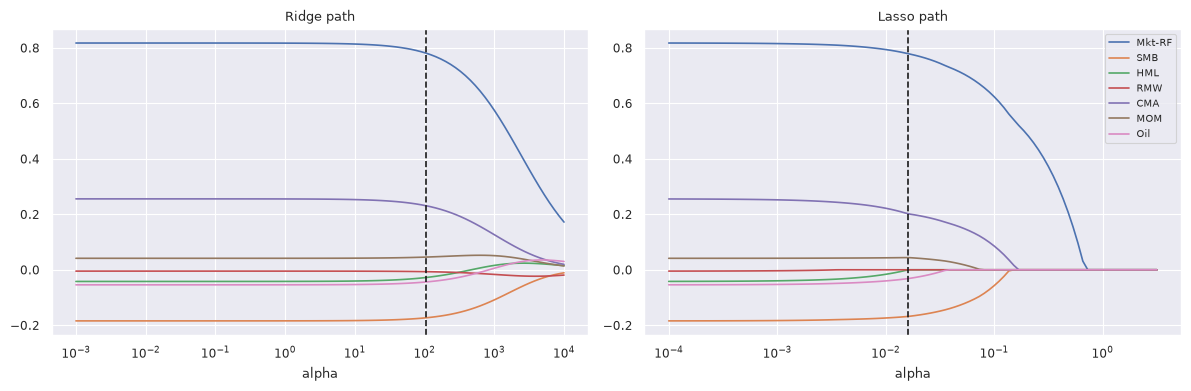

In [145]:
from sklearn.linear_model import Ridge, Lasso

ridge_path = np.array([Ridge(alpha=a).fit(Xs_train, y_train).coef_ for a in alphas_ridge])
lasso_alphas = np.logspace(-4, 0.5, 100)
lasso_path = np.array([Lasso(alpha=a, max_iter=50000).fit(Xs_train, y_train).coef_ for a in lasso_alphas])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(alphas_ridge, ridge_path); axes[0].set_xscale("log")
axes[0].axvline(ridge.alpha_, color="k", ls="--"); axes[0].set_title("Ridge path"); axes[0].set_xlabel("alpha")
axes[1].plot(lasso_alphas, lasso_path, label=factors); axes[1].set_xscale("log")
axes[1].axvline(lasso.alpha_, color="k", ls="--"); axes[1].set_title("Lasso path"); axes[1].set_xlabel("alpha")
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Out-of-sample Performance

In [146]:
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))
def r2_oos(y_true, y_hat, y_bench):
    return 1 - np.sum((y_true - y_hat) ** 2) / np.sum((y_true - y_bench) ** 2)

bench = y_train.mean()   # naive forecast: training mean
results = pd.DataFrame({
    "Test RMSE": [rmse(y_test, ols_pred), rmse(y_test, ridge_pred), rmse(y_test, lasso_pred)],
    "OOS R2 vs mean": [r2_oos(y_test, ols_pred, bench),
                       r2_oos(y_test, ridge_pred, bench),
                       r2_oos(y_test, lasso_pred, bench)],
    "Non-zero factors": [len(factors), len(factors), int((lasso.coef_ != 0).sum())],
}, index=["OLS", "Ridge", "Lasso"])
print(results.round(4))

       Test RMSE  OOS R2 vs mean  Non-zero factors
OLS       1.6268         -0.0132                 7
Ridge     1.6218         -0.0070                 7
Lasso     1.6199         -0.0046                 6


In [147]:
def fit_pred(cols):
    m = sm.OLS(y_train, sm.add_constant(X_train[cols])).fit()
    return m.predict(sm.add_constant(X_test[cols], has_constant="add"))

preds = {
    "CAPM":                    fit_pred(["Mkt-RF"]),
    "FF5":                     fit_pred(ff5_factors),
    "FF5 + MOM":               fit_pred(ff6_factors),
    "FF5 + MOM + Oil (OLS)":   ols_pred,
    "Ridge (all 7)":           pd.Series(ridge_pred, index=y_test.index),
    "Lasso (all 7)":           pd.Series(lasso_pred, index=y_test.index),
}

e_ff5 = (y_test - preds["FF5"]) ** 2
rows = []
for name, p in preds.items():
    e = (y_test - p) ** 2
    d = e_ff5 - e                                   # >0 => model beats FF5
    if name == "FF5":
        t, pv = np.nan, np.nan
    else:
        dm = sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
        t, pv = dm.tvalues[0], dm.pvalues[0]
    rows.append([rmse(y_test, p), r2_oos(y_test, p, bench), t, pv])

bench_table = pd.DataFrame(rows, index=list(preds), columns=["Test RMSE", "OOS R2 vs mean", "DM t vs FF5", "DM p"])
print(bench_table.round(4))

                       Test RMSE  OOS R2 vs mean  DM t vs FF5    DM p
CAPM                      1.6245         -0.0103      -0.3238  0.7461
FF5                       1.6196         -0.0042          NaN     NaN
FF5 + MOM                 1.6290         -0.0159      -4.2167  0.0000
FF5 + MOM + Oil (OLS)     1.6268         -0.0132      -2.8805  0.0040
Ridge (all 7)             1.6218         -0.0070      -0.6351  0.5253
Lasso (all 7)             1.6199         -0.0046      -0.0617  0.9508


          coef    HAC t       p
const   0.0157   0.8480  0.3964
Mkt-RF  0.7136  28.6011  0.0000
SMB    -0.3006  -6.8141  0.0000
HML    -0.0535  -1.1232  0.2613
RMW    -0.0104  -0.1969  0.8439
CMA     0.6141   6.2957  0.0000
MOM     0.0418   1.4664  0.1425
Oil    -0.0204  -2.3463  0.0190


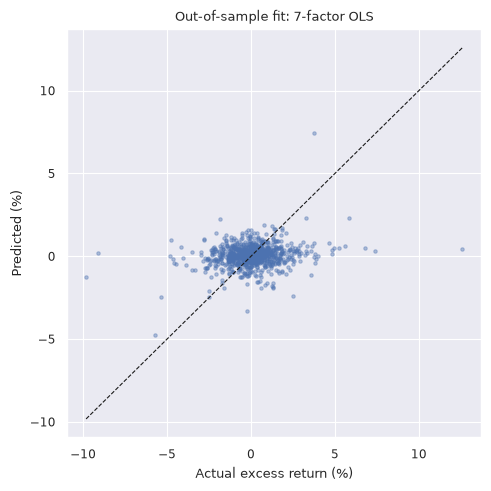

In [148]:
# In-sample view of the extra factors: HAC t-stats of the full 7-factor OLS on the training set
print(pd.DataFrame({"coef": ols.params, "HAC t": ols.tvalues, "p": ols.pvalues}).round(4))

# Predicted vs actual (test set)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, ols_pred, s=6, alpha=0.4)
lims = [min(y_test.min(), ols_pred.min()), max(y_test.max(), ols_pred.max())]
ax.plot(lims, lims, "k--", lw=0.8)
ax.set_xlabel("Actual excess return (%)"); ax.set_ylabel("Predicted (%)")
ax.set_title("Out-of-sample fit: 7-factor OLS")
plt.tight_layout(); plt.show()

In [149]:
# 5E: compare candidate models on ONE common sample (2010 onwards, same rows for every model)
candidates = {
    "CAPM":                    ["Mkt-RF"],
    "FF3 (Mkt, SMB, HML)":     ["Mkt-RF", "SMB", "HML"],
    "FF5":                     ff5_factors,
    "FF5 + MOM":               ff6_factors,
    "FF5 + MOM + Oil":         factors,
    "Mkt + SMB + CMA":         ["Mkt-RF", "SMB", "CMA"],
    "Mkt + SMB + CMA + Oil":   ["Mkt-RF", "SMB", "CMA", "Oil"],
}

rows = []
for name, cols in candidates.items():
    m = sm.OLS(y, sm.add_constant(df[cols])).fit()          # full 2010+ sample
    p = fit_pred(cols)                                      # train -> test prediction
    rows.append([len(cols), m.rsquared_adj, m.aic, m.bic,
                 rmse(y_test, p), r2_oos(y_test, p, bench)])

ic = pd.DataFrame(rows, index=list(candidates),
                  columns=["k", "Adj R2", "AIC", "BIC", "Test RMSE", "OOS R2"])
ic["dBIC"] = ic["BIC"] - ic["BIC"].min()                    # 0 = best by BIC
print(ic.sort_values("BIC").round(4))

                       k  Adj R2         AIC         BIC  Test RMSE  OOS R2  \
Mkt + SMB + CMA + Oil  4  0.2403  13474.4535  13506.1737     1.6126  0.0045   
Mkt + SMB + CMA        3  0.2383  13484.2055  13509.5817     1.6145  0.0020   
FF5                    5  0.2387  13484.0448  13522.1089     1.6196 -0.0042   
FF5 + MOM + Oil        7  0.2409  13473.9031  13524.6554     1.6268 -0.0132   
FF5 + MOM              6  0.2391  13482.9433  13527.3515     1.6290 -0.0159   
FF3 (Mkt, SMB, HML)    3  0.2131  13621.4439  13646.8200     1.6436 -0.0342   
CAPM                   1  0.1987  13695.4492  13708.1373     1.6245 -0.0103   

                           dBIC  
Mkt + SMB + CMA + Oil    0.0000  
Mkt + SMB + CMA          3.4080  
FF5                     15.9352  
FF5 + MOM + Oil         18.4817  
FF5 + MOM               21.1778  
FF3 (Mkt, SMB, HML)    140.6463  
CAPM                   201.9636  


# Question 6 - ARMA Forecasting

## Part A

Text(0.5, 1.0, "Plot of 'MRK' Daily Returns")

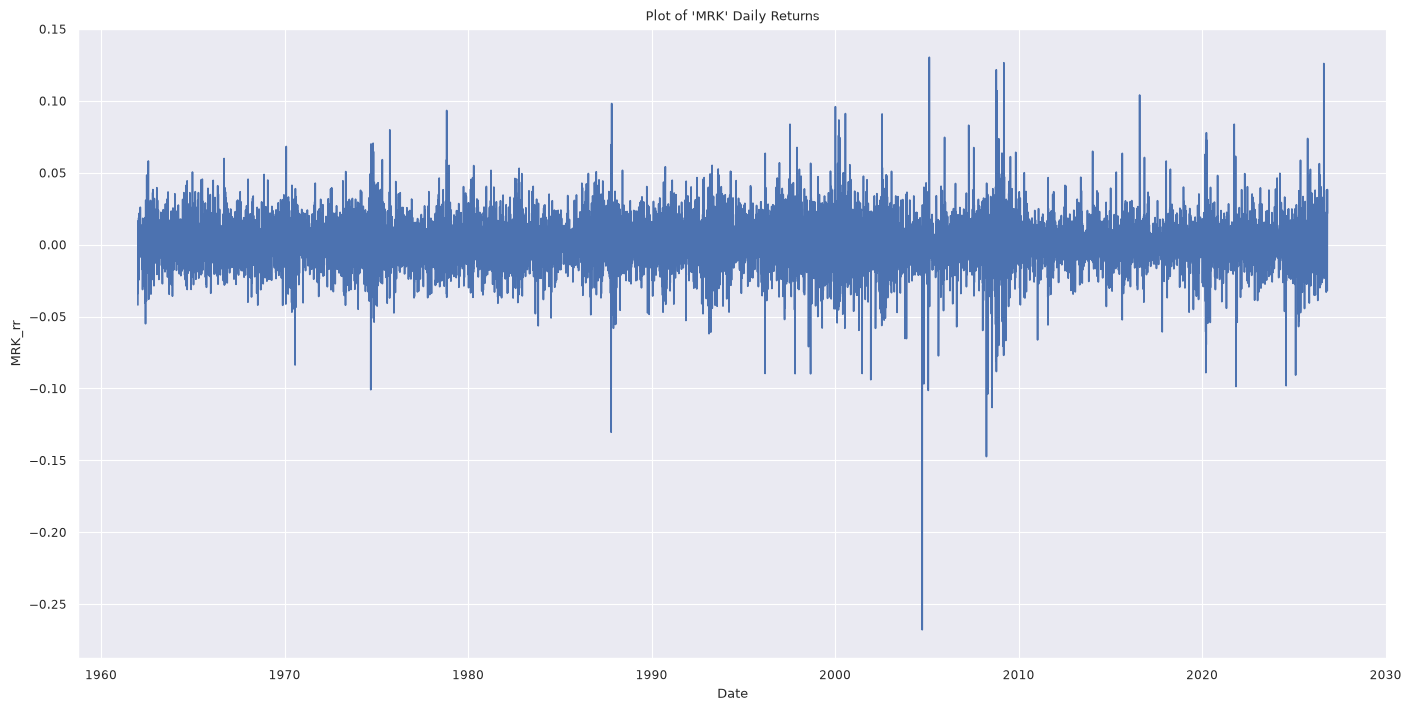

In [150]:
# Plot Return Data
fig, ax = plt.subplots(figsize = (14, 7), layout = 'constrained')

sns.lineplot(mrk_return_daily, ax = ax)

ax.set_title("Plot of 'MRK' Daily Returns")

Text(0.5, 0.98, 'Simple and Sqaured Return ACF & PACF Plots for MERCK&CO., INC.')

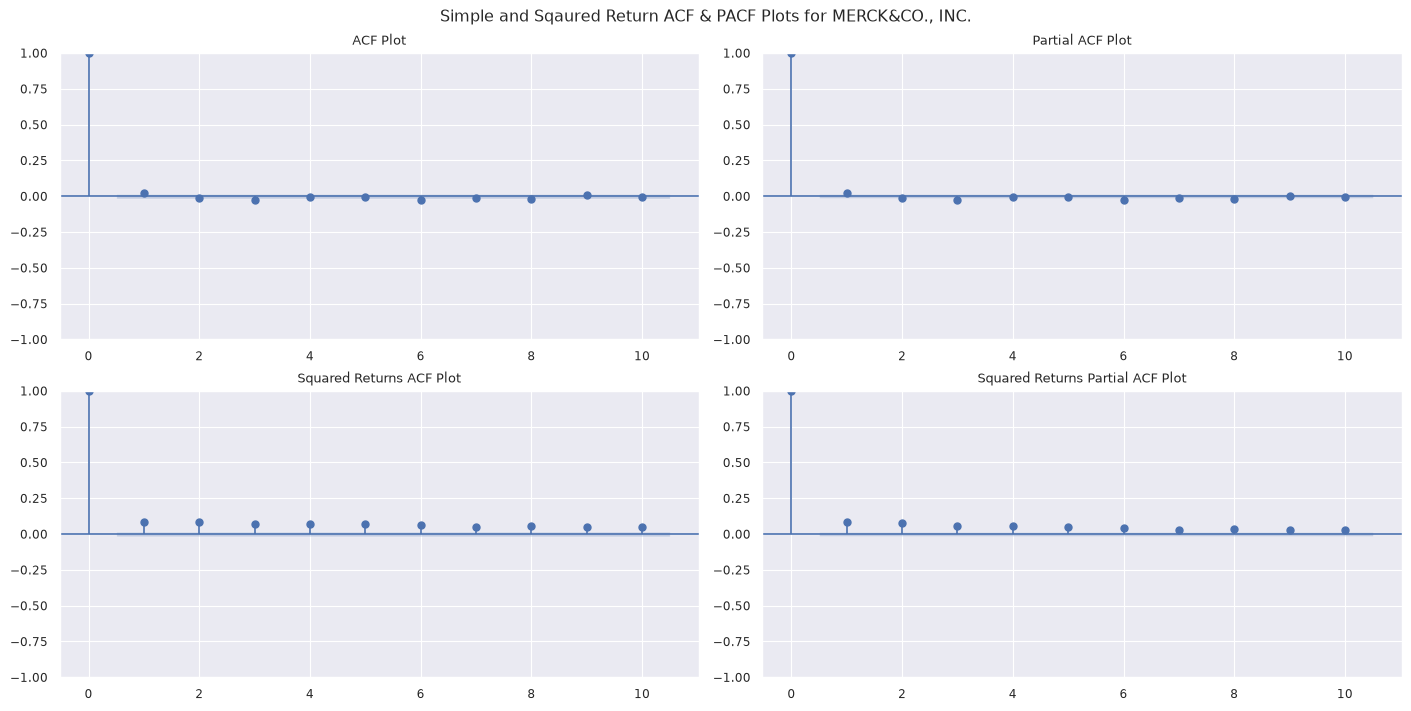

In [151]:
# Compute Squared Simple Returns
mrk_return_daily_squared = np.square(mrk_return_daily)

# Plot both Returns and Squared Returns
fig, axes = plt.subplots(nrows = 2,
                         ncols = 2,
                         figsize = (14, 7),
                         layout = 'constrained')

# Plot ACF
plot_acf(mrk_return_daily, lags = 10, ax = axes[0, 0], alpha = 0.05);
plot_acf(mrk_return_daily_squared, lags = 10, ax = axes[1, 0], alpha = 0.05);
# Plot PACF
plot_pacf(mrk_return_daily, lags = 10, ax = axes[0, 1], alpha = 0.05);
plot_pacf(mrk_return_daily_squared, lags = 10, ax = axes[1, 1], alpha = 0.05);

axes[0, 0].set_title("ACF Plot")
axes[0, 1].set_title("Partial ACF Plot")
axes[1, 0].set_title("Squared Returns ACF Plot")
axes[1, 1].set_title("Squared Returns Partial ACF Plot")

fig.suptitle("Simple and Sqaured Return ACF & PACF Plots for MERCK&CO., INC.")

Cannot see CI, zoom in.

Text(0.5, 0.98, 'Zoomed in Simple Return ACF & PACF Plots for MERCK&CO., INC.')

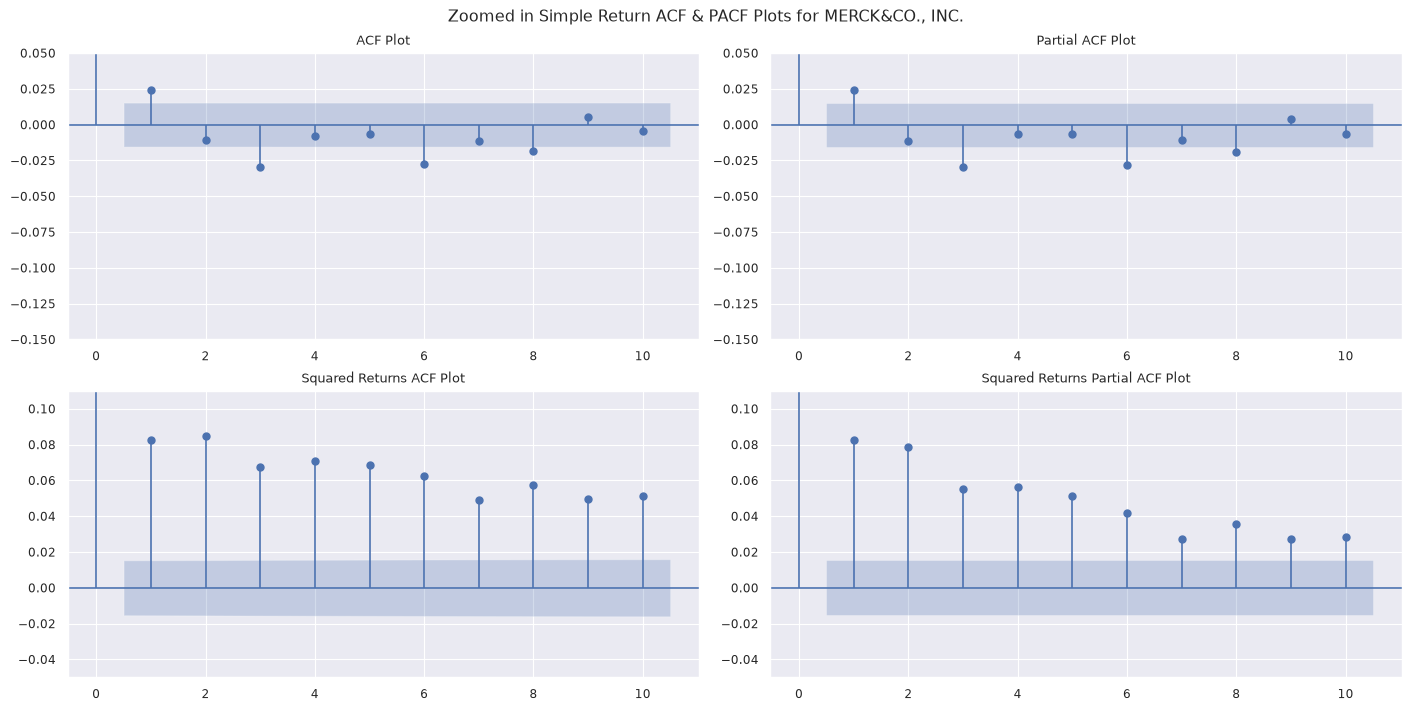

In [152]:
# Compute Squared Simple Returns
mrk_return_daily_squared = np.square(mrk_return_daily)

# Plot both Returns and Squared Returns
fig, axes = plt.subplots(nrows = 2,
                         ncols = 2,
                         figsize = (14, 7),
                         layout = 'constrained')

# Plot ACF
plot_acf(mrk_return_daily, lags = 10, ax = axes[0, 0], alpha = 0.05);
plot_acf(mrk_return_daily_squared, lags = 10, ax = axes[1, 0], alpha = 0.05);
# Plot PACF
plot_pacf(mrk_return_daily, lags = 10, ax = axes[0, 1], alpha = 0.05);
plot_pacf(mrk_return_daily_squared, lags = 10, ax = axes[1, 1], alpha = 0.05);

axes[0, 0].set_title("ACF Plot")
axes[0, 1].set_title("Partial ACF Plot")
axes[1, 0].set_title("Squared Returns ACF Plot")
axes[1, 1].set_title("Squared Returns Partial ACF Plot")

# Zoom only for Simple Returns.
axes[0, 0].set_ylim(-0.15, 0.05)
axes[0, 1].set_ylim(-0.15, 0.05)

# Zoom only for Squared Returns
axes[1, 0].set_ylim(-0.05, 0.11)
axes[1, 1].set_ylim(-0.05, 0.11)

fig.suptitle("Zoomed in Simple Return ACF & PACF Plots for MERCK&CO., INC.")

This looks like white noise?

In [153]:
ljbox_results = acorr_ljungbox(mrk_return_daily, lags = np.arange(1, 11), return_df = False)
print("================================================")
print("Ljung-Box Statistic Results:")
print("================================================")
print(ljbox_results.round(5))
print("================================================")

Ljung-Box Statistic Results:
     lb_stat  lb_pvalue
1    9.51897    0.00203
2   11.39485    0.00335
3   25.98738    0.00001
4   27.07841    0.00002
5   27.72178    0.00004
6   39.91937    0.00000
7   42.07059    0.00000
8   47.53534    0.00000
9   47.98787    0.00000
10  48.32506    0.00000


Rejecting H_0 at 5% significance, it appears that it isnt white noise.

In [154]:
ljbox_results = acorr_ljungbox(mrk_return_daily_squared, lags = np.arange(1, 11), return_df = False)
print("================================================")
print("Ljung-Box Statistic Results:")
print("================================================")
print(ljbox_results.round(5))
print("================================================")

Ljung-Box Statistic Results:
      lb_stat  lb_pvalue
1   111.41710        0.0
2   228.40054        0.0
3   302.66773        0.0
4   385.03391        0.0
5   462.34668        0.0
6   525.46489        0.0
7   564.62749        0.0
8   618.03926        0.0
9   658.12342        0.0
10  701.03117        0.0


In [155]:
# Implement Dickery Fully Test for Stationarity?
adf_result = adfuller(mrk_return_daily, regression = 'c')
print("================================================")
print("ADF Results w/ constant")
print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")
print("================================================")
adf_result = adfuller(mrk_return_daily, regression = 'ct')
print("================================================")
print("ADF Results w/ constant & linear trend")
print(f"ADF Statistic: {adf_result[0]}")
print(f"p-value: {adf_result[1]}")
print("================================================")

/tmp/ipykernel_1450/1337880083.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(mrk_return_daily, regression = 'c')


ADF Results w/ constant
ADF Statistic: -26.88823933350894
p-value: 0.0
ADF Results w/ constant & linear trend
ADF Statistic: -26.89338843828452
p-value: 0.0


/tmp/ipykernel_1450/1337880083.py:8: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(mrk_return_daily, regression = 'ct')


Does appear to be stationary based on the Dick Fully test, reject H_0 at 5% significance.

## Part B

In [156]:
# Daily return series for Part 6 ARMA section
mrk_return_daily = ff3_mrk['MRK_rr'].dropna().copy()

print(mrk_return_daily.head())
print(mrk_return_daily.shape)

Date
1962-01-03   -0.041900
1962-01-04   -0.010203
1962-01-05   -0.033874
1962-01-08    0.003048
1962-01-09    0.004560
Name: MRK_rr, dtype: float64
(16172,)


In [157]:
# Define ARMA fit function.
def fit_ARMA(data, p, q):
    model = ARIMA(data, order = (p, 0, q))
    return model.fit()

In [158]:
# Use tuples to specify ARMA(p, q).
processes = [(0, 1), (1, 0), (1,1)]

In [159]:
# Compare ARMA models using BIC

arma_results = []
fitted_models = {}

for p, q in processes:
    print(f"Fitting ARMA({p}, {q})")

    model = fit_ARMA(mrk_return_daily, p, q)

    fitted_models[(p, q)] = model

    arma_results.append({
        'Model': f'ARMA({p},{q})',
        'p': p,
        'q': q,
        'BIC': model.bic
    })

# Compare BIC values
bic_table = pd.DataFrame(arma_results)
bic_table = bic_table.sort_values('BIC')

print(bic_table)

# Select the model with the lowest BIC
best_p = int(bic_table.iloc[0]['p'])
best_q = int(bic_table.iloc[0]['q'])

best_model = fitted_models[(best_p, best_q)]

print(f"\nBest model: ARMA({best_p},{best_q})")
print(best_model.summary())

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


Fitting ARMA(0, 1)
Fitting ARMA(1, 0)


/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


Fitting ARMA(1, 1)


/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


       Model  p  q           BIC
0  ARMA(0,1)  0  1 -88421.081079
1  ARMA(1,0)  1  0 -88420.842592
2  ARMA(1,1)  1  1 -88410.645266

Best model: ARMA(0,1)
                               SARIMAX Results                                
Dep. Variable:                 MRK_rr   No. Observations:                16172
Model:                 ARIMA(0, 0, 1)   Log Likelihood               44225.077
Date:                Sun, 01 Nov 2026   AIC                         -88444.154
Time:                        05:23:39   BIC                         -88421.081
Sample:                             0   HQIC                        -88436.527
                              - 16172                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0006      0.000      4.543      0.000 

## Part C

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, bu

Text(0, 0.5, 'Returns')

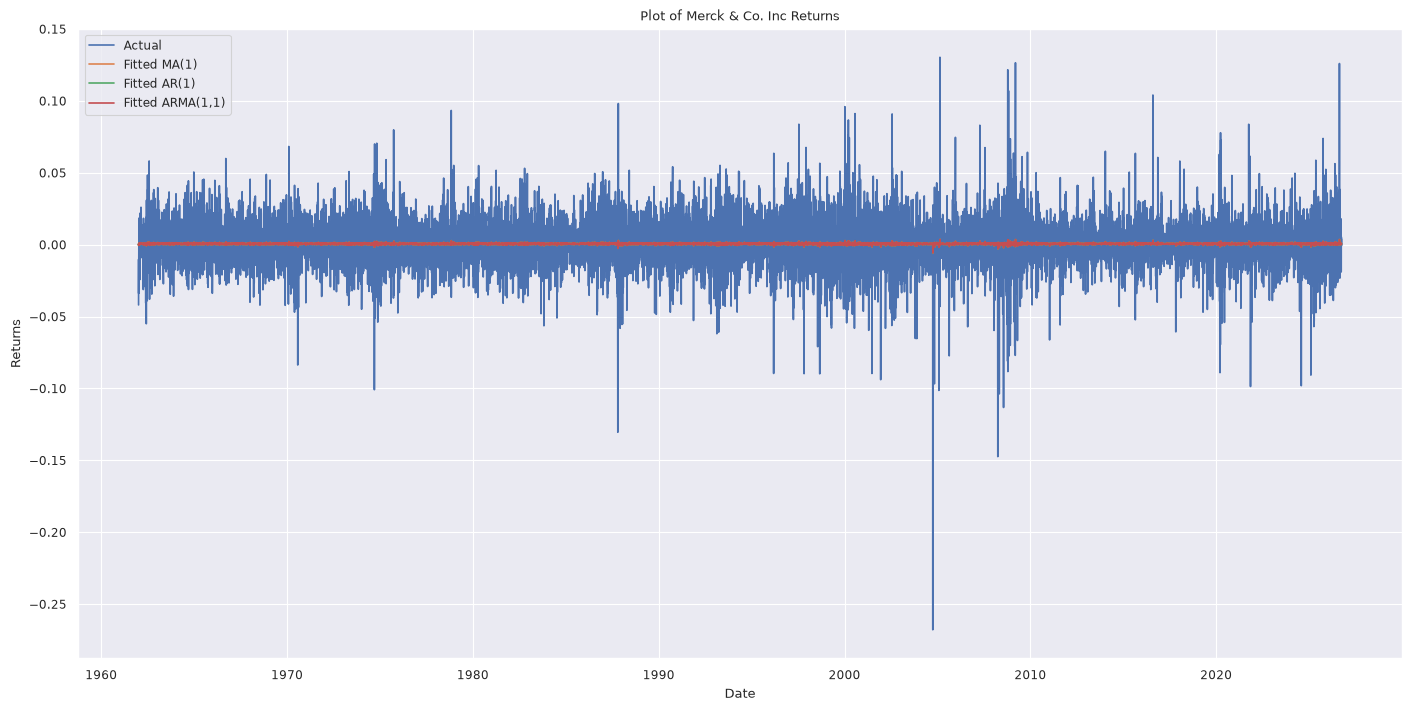

In [182]:
# Fit ARMA(0, 1)
model_results_0_1 = fit_ARMA(mrk_return_daily, 0, 1)
model_results_1_0 = fit_ARMA(mrk_return_daily, 1, 0)
model_results_1_1 = fit_ARMA(mrk_return_daily, 1, 1)

# Plot Fitted and Actual Data
fig, ax = plt.subplots(figsize = (14, 7), layout = 'constrained')

sns.lineplot(mrk_return_daily, ax = ax, label = 'Actual')
sns.lineplot(model_results_0_1.fittedvalues, ax = ax, label = 'Fitted MA(1)')
sns.lineplot(model_results_1_0.fittedvalues, ax = ax, label = 'Fitted AR(1)')
sns.lineplot(model_results_1_1.fittedvalues, ax = ax, label = 'Fitted ARMA(1,1)')

ax.set_title("Plot of Merck & Co. Inc Returns")
ax.set_ylabel("Returns")

Text(0.5, 1.0, 'Plot of MA(1) residuals')

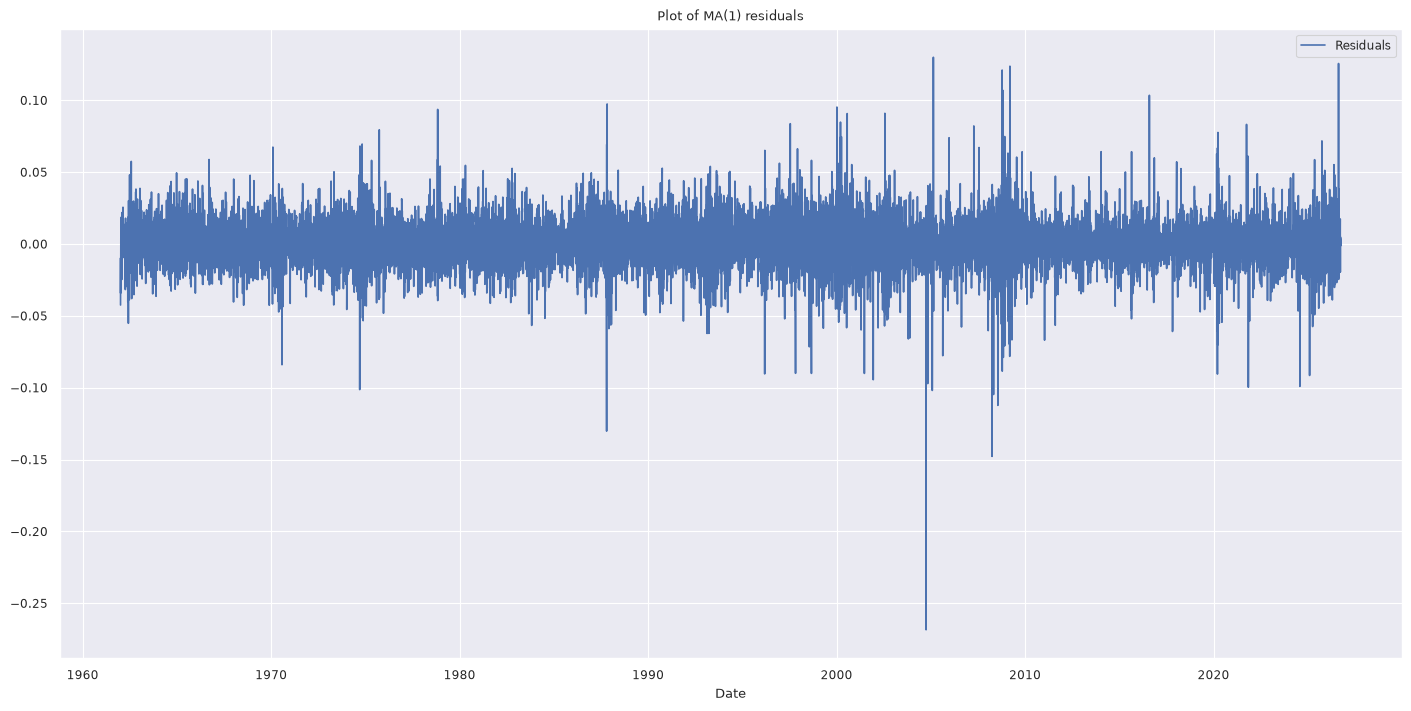

In [172]:
fig, ax = plt.subplots(figsize = (14, 7), layout = 'constrained')

sns.lineplot(model_results_0_1.resid, ax = ax, label = 'Residuals')
ax.set_title("Plot of MA(1) residuals")

In [162]:
# Part 6(c) - BDS test on ARMA residuals

from statsmodels.tsa.stattools import bds

# Residuals from the selected ARMA model
residuals = best_model.resid.dropna()

# Implement BDS Test
bds_stat, bds_p_val = bds(residuals, max_dim = 2)

print(f"The F-Statistic for BDS is: {bds_stat:.2}")
print(f"The p-value for BDS is: {bds_p_val:.2}")

The F-Statistic for BDS is: 2.3e+01
The p-value for BDS is: 1.8e-117


## Part D

In [163]:
# Part 6(d) - Analytical long-run forecast

# Long-run expected return for the selected ARMA model
long_run_mean = best_model.params['const']

print(f"Selected model: ARMA({best_p},{best_q})")
print(f"Analytical long-run daily return: {long_run_mean:.6f}")

Selected model: ARMA(0,1)
Analytical long-run daily return: 0.000576


Analytical long-run mean: 0.000576
Forecast at step 1000: 0.000576


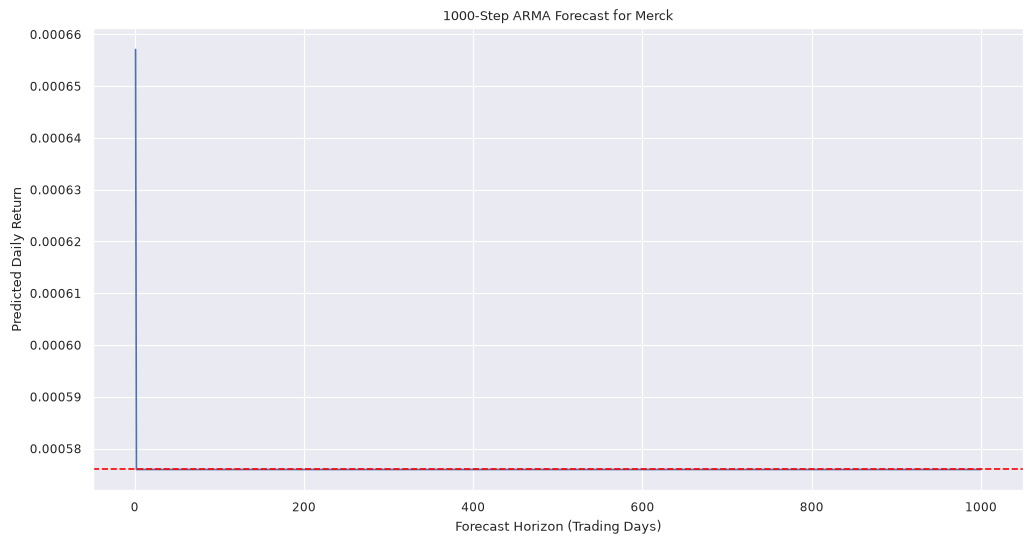

In [180]:
# Part 6(d) - 1000-step dynamic forecast

# Refit the selected ARMA model using a numerical index
returns_for_forecast = mrk_return_daily.dropna().reset_index(drop=True)

forecast_model = fit_ARMA(returns_for_forecast, best_p, best_q)

# Forecast the next 1000 trading periods
forecast_1000 = forecast_model.get_forecast(steps=1000)
forecast_values = forecast_1000.predicted_mean

# Plot forecasts and analytical long-run mean
plt.figure(figsize=(12, 6))

plt.plot(range(1, 1001), forecast_values,
         label='ARMA Forecast')

plt.axhline(y=long_run_mean, color='red',
            linestyle='--', label='Long-run Mean')

plt.xlabel('Forecast Horizon (Trading Days)')
plt.ylabel('Predicted Daily Return')
plt.title('1000-Step ARMA Forecast for Merck')

print(f"Analytical long-run mean: {long_run_mean:.6f}")
print(f"Forecast at step 1000: {forecast_values.iloc[-1]:.6f}")

## Part E

In [165]:
# Part 6(e) - Split returns into training and test sets

returns = mrk_return_daily.dropna().reset_index(drop=True)

# Last 100 observations are used for testing
train_returns = returns.iloc[:-100]
test_returns = returns.iloc[-100:]

print("Training observations:", len(train_returns))
print("Testing observations:", len(test_returns))

Training observations: 16072
Testing observations: 100


In [166]:
# Part 6(e) - Select ARMA model using training data

train_results = []
train_models = {}

for p, q in processes:

    model = fit_ARMA(train_returns, p, q)

    train_models[(p, q)] = model

    train_results.append({
        'Model': f'ARMA({p},{q})',
        'p': p,
        'q': q,
        'BIC': model.bic
    })

# Compare BIC values
train_bic_table = pd.DataFrame(train_results)
train_bic_table = train_bic_table.sort_values('BIC')

print(train_bic_table)

# Choose the model with the lowest BIC
train_best_p = int(train_bic_table.iloc[0]['p'])
train_best_q = int(train_bic_table.iloc[0]['q'])

train_best_model = train_models[(train_best_p, train_best_q)]

print(f"\nBest training model: ARMA({train_best_p},{train_best_q})")

/home/eddie/miniforge3/envs/ECON3206_env/lib/python3.15/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


       Model  p  q           BIC
0  ARMA(0,1)  0  1 -87955.946897
1  ARMA(1,0)  1  0 -87955.658384
2  ARMA(1,1)  1  1 -87945.890518

Best training model: ARMA(0,1)


In [167]:
# Part 6(e) - Forecast the final 100 daily returns

# Generate 100 out-of-sample forecasts
forecast_100 = train_best_model.get_forecast(steps=100)

# Predicted returns and 95% prediction intervals
predicted_returns = forecast_100.predicted_mean
forecast_intervals = forecast_100.conf_int(alpha=0.05)

# Extract lower and upper bounds
lower_bound = forecast_intervals.iloc[:, 0]
upper_bound = forecast_intervals.iloc[:, 1]

print("First 5 predicted returns:")
print(predicted_returns.head())

print("\nFirst 5 prediction intervals:")
print(forecast_intervals.head())

First 5 predicted returns:
16072    0.000637
16073    0.000560
16074    0.000560
16075    0.000560
16076    0.000560
Name: predicted_mean, dtype: float64

First 5 prediction intervals:
       lower MRK_rr  upper MRK_rr
16072     -0.030063      0.031338
16073     -0.030150      0.031270
16074     -0.030150      0.031270
16075     -0.030150      0.031270
16076     -0.030150      0.031270


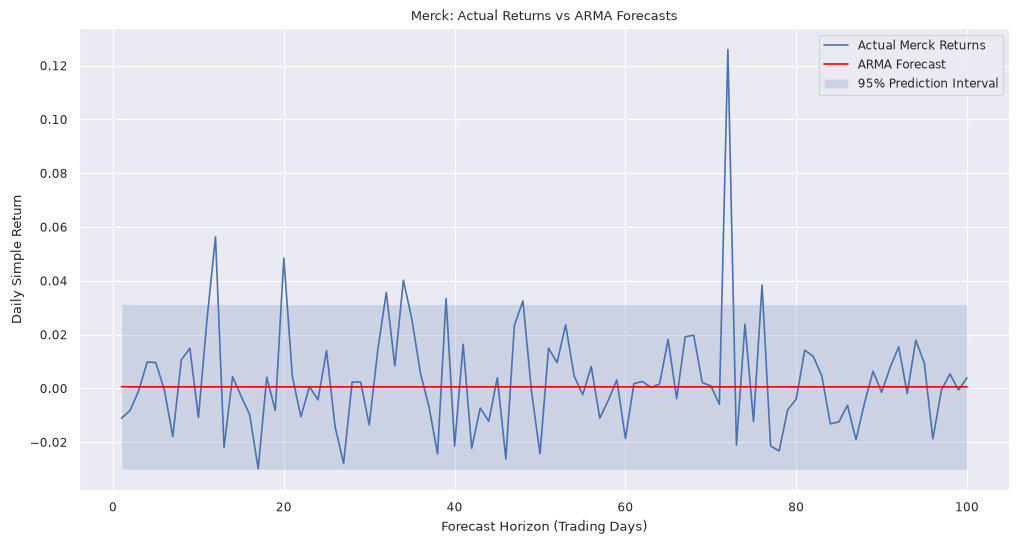

In [168]:
# Part 6(e) - Plot actual returns and ARMA forecasts

# Forecast periods from 1 to 100
forecast_days = range(1, 101)

plt.figure(figsize=(12, 6))

# Actual returns
plt.plot(forecast_days, test_returns.values,
         label='Actual Merck Returns')

# Forecasted returns
plt.plot(forecast_days, predicted_returns.values,
         label='ARMA Forecast', color='red')

# 95% prediction intervals
plt.fill_between(forecast_days,
                 lower_bound.values,
                 upper_bound.values,
                 alpha=0.2,
                 label='95% Prediction Interval')

plt.xlabel('Forecast Horizon (Trading Days)')
plt.ylabel('Daily Simple Return')
plt.title('Merck: Actual Returns vs ARMA Forecasts')
plt.legend()
plt.show()

In [169]:
# Part 6(e) - Calculate ARMA forecast RMSE

# Compare actual returns with predicted returns
forecast_errors = test_returns.values - predicted_returns.values

# Root Mean Squared Error
arma_rmse = np.sqrt(np.mean(forecast_errors ** 2))

print(f"ARMA({train_best_p},{train_best_q}) RMSE: {arma_rmse:.6f}")

ARMA(0,1) RMSE: 0.021108


## Part F

In [170]:
# Part 6(f) - Normal white noise benchmark

# Estimate mean and standard deviation using training data
wn_mean = train_returns.mean()
wn_std = train_returns.std()

# White noise forecast is the training sample mean
wn_forecast = np.repeat(wn_mean, 100)

# Calculate white noise forecast RMSE
wn_errors = test_returns.values - wn_forecast
wn_rmse = np.sqrt(np.mean(wn_errors ** 2))

print(f"White noise mean: {wn_mean:.6f}")
print(f"White noise standard deviation: {wn_std:.6f}")

print(f"ARMA RMSE: {arma_rmse:.6f}")
print(f"White noise RMSE: {wn_rmse:.6f}")

White noise mean: 0.000560
White noise standard deviation: 0.015673
ARMA RMSE: 0.021108
White noise RMSE: 0.021107


In [171]:
# Compare forecasting accuracy more precisely

print(f"ARMA RMSE: {arma_rmse:.10f}")
print(f"White noise RMSE: {wn_rmse:.10f}")

rmse_difference = arma_rmse - wn_rmse

print(f"RMSE difference: {rmse_difference:.10f}")

ARMA RMSE: 0.0211077615
White noise RMSE: 0.0211073344
RMSE difference: 0.0000004271
